# From data to decision: a small demo

Companion notebook for the guest lecture "Big Data Analytics and
Predictive Modeling for Decision Intelligence".

It walks through one example, a delivery service that must decide how
many couriers to schedule for each day:

1. make the data: three years of daily orders;
2. split it by time and build features;
3. compare a baseline with gradient boosting (MAE, MAPE);
4. forecast a range (quantiles), not one number;
5. turn the forecast into a decision and count the cost.

**The data is synthetic.** It is generated in the first code cell, so you
can see every rule behind it. The numbers are not real company data, but
the method is the one used in practice.

Run all cells: *Runtime -> Run all* in Google Colab. It takes a few
seconds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

## 1. Data

Daily orders depend on four things: the day of the week (Friday and
Saturday are busy), public holidays (fewer orders; a two-day holiday
moves to different dates every year), rain (fewer orders, more often in the wet
season) and random noise of about 6%.

In [2]:
rng = np.random.default_rng(42)
days = pd.date_range("2023-01-01", "2025-12-31", freq="D")
n = len(days)

# Monday .. Sunday
week = np.array([0.92, 0.95, 1.00, 1.02, 1.18, 1.25, 0.88])
holidays = pd.to_datetime([
    "2023-01-01", "2023-04-21", "2023-04-22", "2023-05-01",
    "2023-06-01", "2023-08-17",
    "2024-01-01", "2024-04-10", "2024-04-11", "2024-05-01",
    "2024-06-01", "2024-08-17",
    "2025-01-01", "2025-03-31", "2025-04-01", "2025-05-01",
    "2025-06-01", "2025-08-17", "2025-11-10"])

df = pd.DataFrame({"date": days})
df["dow"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month
df["holiday"] = df["date"].isin(holidays).astype(int)
wet = df["month"].isin([11, 12, 1, 2, 3])
df["rain"] = (rng.random(n) < np.where(wet, 0.45, 0.12)).astype(int)

level = 1000 * week[df["dow"]]
level = level * (1 - 0.35 * df["holiday"]) * (1 - 0.10 * df["rain"])
noise = rng.normal(0, 0.06, n)
df["orders"] = np.round(level * (1 + noise)).astype(int)

print(df.tail(7).to_string(index=False))

      date  dow  month  holiday  rain  orders
2025-12-25    3     12        0     0    1016
2025-12-26    4     12        0     1    1109
2025-12-27    5     12        0     0    1186
2025-12-28    6     12        0     1     741
2025-12-29    0     12        0     1     839
2025-12-30    1     12        0     0     984
2025-12-31    2     12        0     1     918


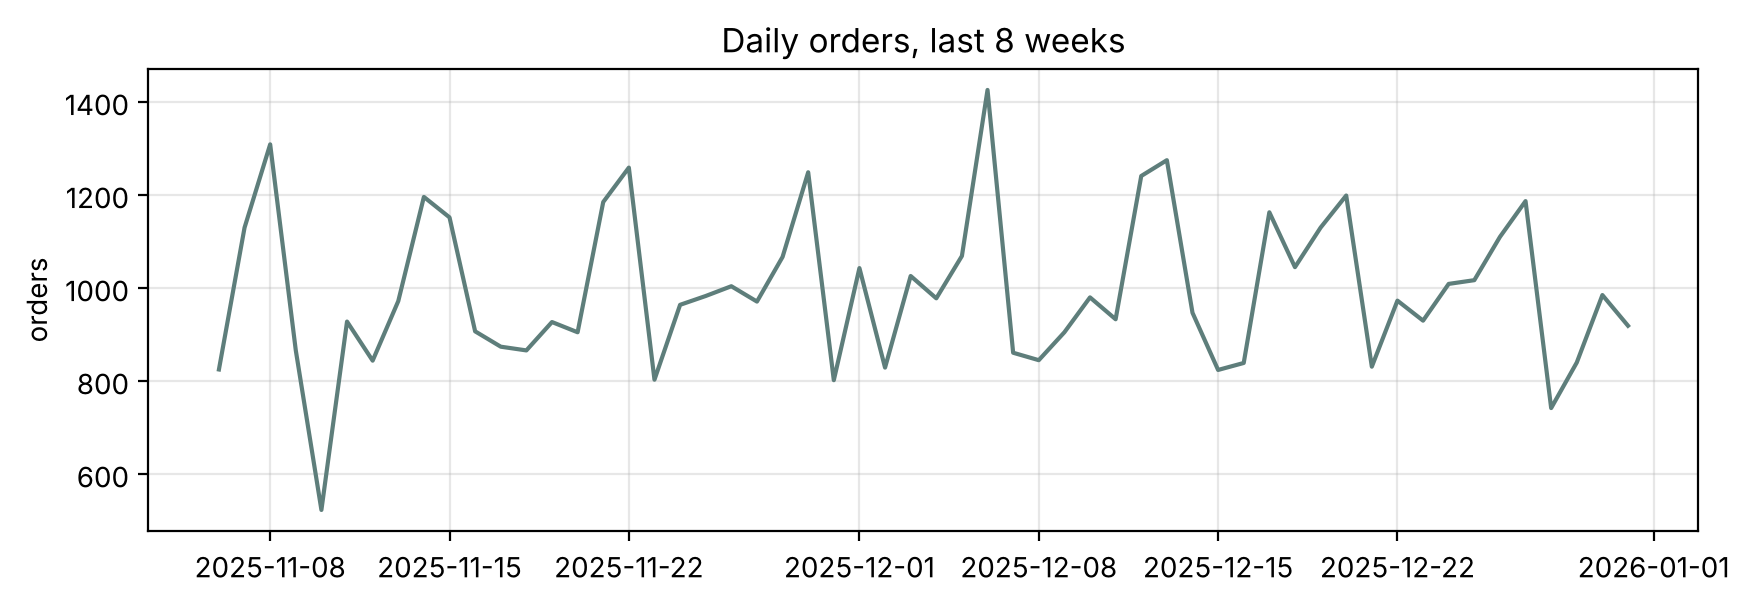

In [3]:
last = df.tail(56)
plt.figure(figsize=(10, 3))
plt.plot(last["date"], last["orders"], color="#5E7E7B")
plt.title("Daily orders, last 8 weeks")
plt.ylabel("orders")
plt.grid(alpha=0.3)
plt.show()

## 2. Features and a time-based split

We forecast up to 7 days ahead, so the model may use only what is known
a week before: the calendar, the holiday list, the weather forecast and
the orders from 7 and 14 days ago (lag features). Here we assume the
rain forecast is correct; in real life it adds its own error.

The split follows time: train on the past, tune on the validation
period, test once on the newest three months.

In [4]:
df["lag7"] = df["orders"].shift(7)
df["lag14"] = df["orders"].shift(14)
df["mean_prev_week"] = df["orders"].shift(7).rolling(7).mean()
df = df.dropna().reset_index(drop=True)

features = ["dow", "month", "holiday", "rain",
            "lag7", "lag14", "mean_prev_week"]

train = df[df["date"] < "2025-07-01"]
valid = df[(df["date"] >= "2025-07-01") & (df["date"] < "2025-10-01")]
test = df[df["date"] >= "2025-10-01"]
print("train:", len(train), " validation:", len(valid),
      " test:", len(test))

train: 898  validation: 92  test: 92


## 3. Baseline against gradient boosting

The baseline says: "the same as on this day last week". The model is
gradient boosting from scikit-learn. Its settings (tree depth, number of
trees) were chosen on the validation period, and the test period is used
only for the final numbers.

In [5]:
def mae(y, p):
    return float(np.mean(np.abs(y - p)))


def mape(y, p):
    return float(np.mean(np.abs(y - p) / y) * 100)


def fit(quantile, data):
    model = HistGradientBoostingRegressor(
        loss="quantile", quantile=quantile, max_iter=200,
        learning_rate=0.05, max_depth=3, min_samples_leaf=10,
        random_state=0)
    return model.fit(data[features], data["orders"])


rows = []
for name, past, part in (("validation", train, valid),
                         ("test", pd.concat([train, valid]), test)):
    y = part["orders"]
    p = fit(0.5, past).predict(part[features])
    rows.append((name, "baseline", mae(y, part["lag7"]),
                 mape(y, part["lag7"])))
    rows.append((name, "gradient boosting", mae(y, p), mape(y, p)))

result = pd.DataFrame(rows, columns=["period", "model", "MAE", "MAPE, %"])
print(result.round(1).to_string(index=False))

    period             model  MAE  MAPE, %
validation          baseline 79.4      8.1
validation gradient boosting 50.5      4.9
      test          baseline 82.8      8.7
      test gradient boosting 41.5      4.2


## 4. Forecast a range

The same model can predict quantiles. We train four models: for the
10th, 50th (median), 75th and 90th percentile. Then we check on the test
period how often the real value falls inside the 10-90 range. It should
be close to 80%.

In [6]:
past = pd.concat([train, valid])
quantiles = (0.10, 0.50, 0.75, 0.90)
pred = {q: fit(q, past).predict(test[features]) for q in quantiles}
y = test["orders"].to_numpy()

inside = np.mean((y >= pred[0.10]) & (y <= pred[0.90]))
below75 = np.mean(y <= pred[0.75])
print(f"Inside the 10-90 range: {inside:.0%} of test days")
print(f"At or below the 75th percentile: {below75:.0%} of test days")

Inside the 10-90 range: 84% of test days
At or below the 75th percentile: 79% of test days


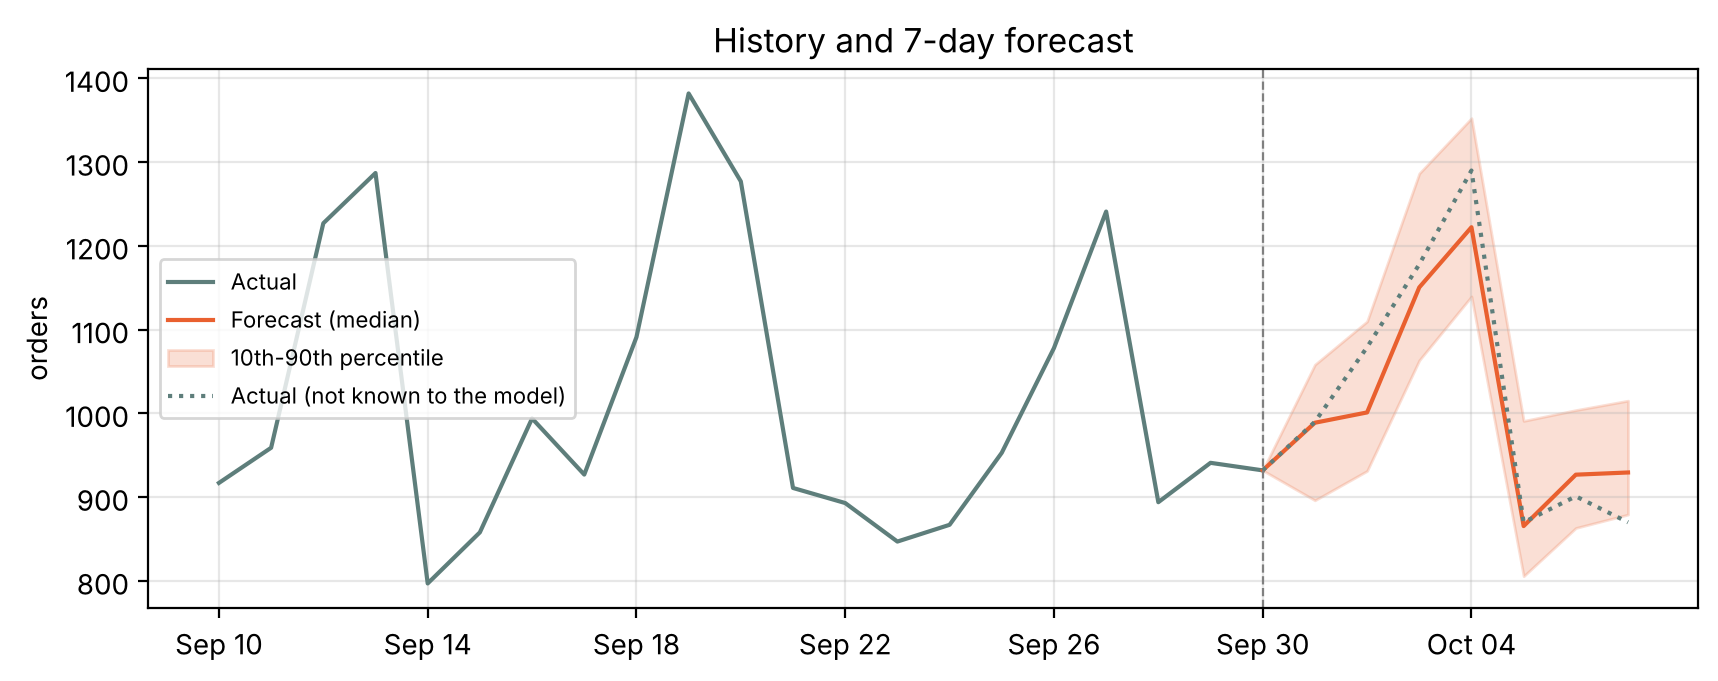

In [7]:
hist = past.tail(21)
week7 = test.head(7)
k = slice(0, 7)

# The forecast lines start at the last known day, so there is no gap
last = hist.tail(1)
fc_dates = pd.concat([last["date"], week7["date"]])
y0 = last["orders"].to_numpy()

plt.figure(figsize=(10, 3.5))
plt.plot(hist["date"], hist["orders"], color="#5E7E7B", label="Actual")
plt.plot(fc_dates, np.r_[y0, pred[0.50][k]], color="#E9602F",
         label="Forecast (median)")
plt.fill_between(fc_dates, np.r_[y0, pred[0.10][k]],
                 np.r_[y0, pred[0.90][k]], color="#E9602F", alpha=0.2,
                 label="10th-90th percentile")
plt.plot(fc_dates, np.r_[y0, week7["orders"]], color="#5E7E7B",
         linestyle=":", label="Actual (not known to the model)")
plt.axvline(last["date"].iloc[0], color="gray", linewidth=0.8,
            linestyle="--")
ticks = pd.date_range(hist["date"].iloc[0], week7["date"].iloc[-1],
                      freq="4D")
plt.xticks(ticks, ticks.strftime("%b %d"))
plt.title("History and 7-day forecast")
plt.ylabel("orders")
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()

## 5. From forecast to decision

We schedule couriers for a planned number of orders. Each order we
cannot deliver costs 3 units; each unused slot costs 1 unit. The
newsvendor rule gives the quantile to plan for: 3 / (3 + 1) = 0.75.

Below is the total cost over the test period for four plans.

In [8]:
COST_SHORT = 3   # one lost order
COST_EXTRA = 1   # one unused delivery slot


def total_cost(plan):
    short = np.maximum(y - plan, 0)
    extra = np.maximum(plan - y, 0)
    return int(round(np.sum(COST_SHORT * short + COST_EXTRA * extra)))


plans = [("Baseline: same day last week", test["lag7"].to_numpy()),
         ("Model, median (50th percentile)", pred[0.50]),
         ("Model, 75th percentile", pred[0.75]),
         ("Model, 90th percentile", pred[0.90])]
costs = pd.DataFrame(
    [(name, total_cost(plan)) for name, plan in plans],
    columns=["plan", "total cost"])
base = costs["total cost"].iloc[0]
costs["vs baseline, %"] = (
    (costs["total cost"] / base * 100 - 100).round().astype(int))
print(costs.to_string(index=False))

                           plan  total cost  vs baseline, %
   Baseline: same day last week       15117               0
Model, median (50th percentile)        8650             -43
         Model, 75th percentile        6149             -59
         Model, 90th percentile        7980             -47


## What to notice

- The model beats the baseline on error and on cost.
- With the same model, planning for the 75th percentile is cheaper than
  planning for the median. The decision rule gives a second saving.
- The 90th percentile is too careful here: we pay for idle couriers.
- The forecast gives the range; the costs choose the point.

## Try it yourself

1. Change `COST_SHORT` to 9. Which quantile is best now? (9 / (9 + 1) = 0.9)
2. Remove `"holiday"` from `features`. What happens to the error?
3. Replace the time-based split with a random one. Why do the numbers
   look better, and why is that misleading?
4. Add a slow growth trend to the data (for example `* (1 + 0.0004 * t)`).
   Tree models cannot extrapolate a trend. How would you fix it?